# Prac 06.1

For this homework we are not going to provide you with any code, you'll have to build the face detector on your own.

### Step 0

Run the necessary imports.

In [1]:
import cv2
import dlib
import numpy as np
import matplotlib.pyplot as plt

### Step 1

Load an image (any image that contains faces).

In [2]:
# Load image using OpenCV
image_path = "../data/zelensky.jpg"
img = cv2.imread(image_path)

# Convert BGR (OpenCV default) to RGB for Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale for dlib detection
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

### Step 2

Load the dlib face predictor.

In [3]:
# Load dlib's default HOG-based frontal face detector
detector = dlib.get_frontal_face_detector()

### Step 3

Run the predictor on your image.

In [4]:
# The second parameter (1) upsamples the image 1 time to help detect smaller faces
detected_faces = detector(gray, 1)

print(f"Total faces detected: {len(detected_faces)}")

Total faces detected: 1


### Step 4

Draw bounding boxes around the detected faces and plot the image. Use different colour for each face.

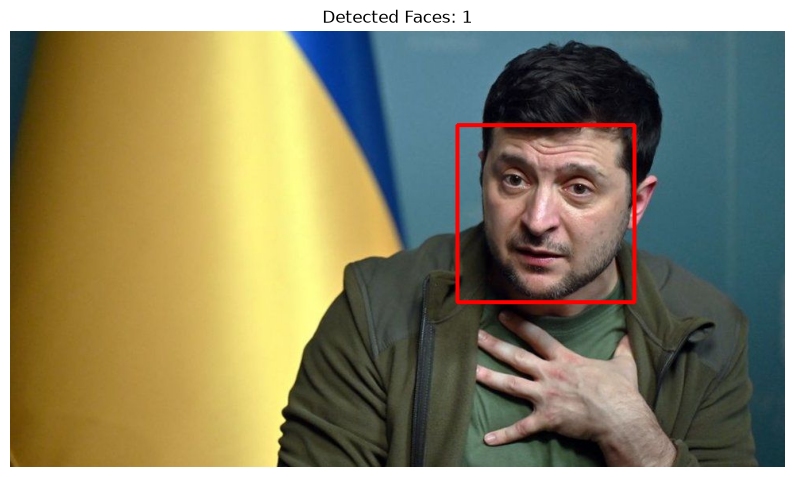

In [5]:
# Create a copy of the image for drawing
annotated_img = img_rgb.copy()

# Generate a unique RGB color for each detected face using matplotlib colormap
cmap = plt.get_cmap("hsv")
colors = [np.array(cmap(i / max(len(detected_faces), 1))[:3]) * 255 for i in range(len(detected_faces))]

for i, rect in enumerate(detected_faces):
    # Extract coordinates from dlib.rectangle object
    x1, y1 = rect.left(), rect.top()
    x2, y2 = rect.right(), rect.bottom()
    
    # Get assigned color as an integer tuple
    color = tuple(int(c) for c in colors[i])
    
    # Draw rectangle on image
    cv2.rectangle(annotated_img, (x1, y1), (x2, y2), color, thickness=3)

# Display the image
plt.figure(figsize=(10, 8))
plt.imshow(annotated_img)
plt.axis("off")
plt.title(f"Detected Faces: {len(detected_faces)}")
plt.show()

### Step 5 (optional)

Repeat the process with a different and more challenging image (more faces, smaller faces, people with glasses, hats, helmets, etc.). How does the detector perform? Is it robust?

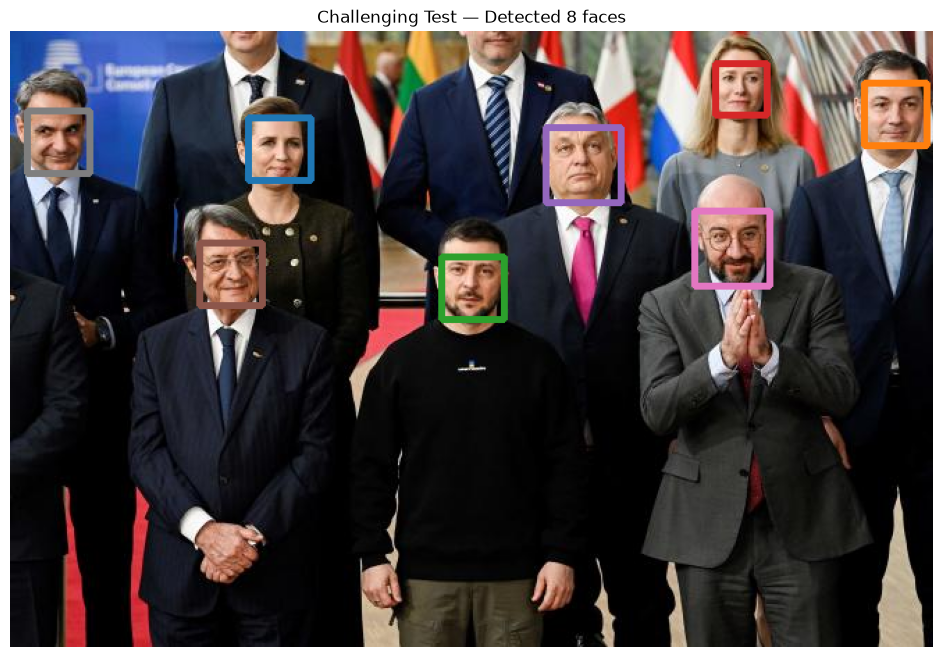

In [6]:
def detect_and_plot(image_path):
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error loading {image_path}")
        return
        
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Higher upsample value (e.g., 2) detects smaller faces at the cost of speed
    faces = detector(gray, 2)
    
    cmap = plt.get_cmap("tab10")
    annotated = img_rgb.copy()
    
    for i, rect in enumerate(faces):
        color = tuple(int(c * 255) for c in cmap(i % 10)[:3])
        cv2.rectangle(annotated, (rect.left(), rect.top()), (rect.right(), rect.bottom()), color, 3)
        
    plt.figure(figsize=(12, 8))
    plt.imshow(annotated)
    plt.axis("off")
    plt.title(f"Challenging Test — Detected {len(faces)} faces")
    plt.show()

# Run on a complex image
detect_and_plot("../data/eu_summit.jpg")